In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DAY7_DIR = Path(r"C:\Users\Comp\Linkific-Tasks-Upload\Day 7")
DATA_FILE = DAY7_DIR / "data" / "ecommerce_sales.csv"
OUTPUT_DIR = DAY7_DIR / "outputs"
REPORT_DIR = DAY7_DIR / "reports"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
df["sales"] = df["quantity"] * df["unit_price"]
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

# Remove repeated order IDs for customer analysis
df = df.drop_duplicates(subset=["order_id"], keep="first")

print("Dataset rows after duplicate-order removal:", len(df))
display(df.head())


Dataset rows after duplicate-order removal: 12


,order_id,customer,category,quantity,unit_price,order_date,rating,sales
0,1001,Asha,Electronics,2,1200,2026-01-05,5.0,2400
1,1002,Rahul,Clothing,3,500,2026-01-08,4.0,1500
2,1003,Meera,Electronics,1,2500,2026-01-12,5.0,2500
3,1004,Arjun,Home,2,800,2026-01-15,3.0,1600
4,1005,Asha,Clothing,4,450,2026-02-02,4.0,1800


In [2]:

customer_summary = (
    df.groupby("customer")
    .agg(
        order_count=("order_id", "nunique"),
        total_spent=("sales", "sum"),
        average_order_value=("sales", "mean"),
        total_units=("quantity", "sum")
    )
    .sort_values("total_spent", ascending=False)
    .round(2)
)

display(customer_summary)

customer_summary.to_csv(
    OUTPUT_DIR / "customer_behavior_summary.csv"
)


,order_count,total_spent,average_order_value,total_units
customer,,,,
Meera,3,6600,2200.0,4
Asha,3,6000,2000.0,7
Arjun,2,3400,1700.0,5
Kiran,2,2800,1400.0,4
Rahul,2,2700,1350.0,4


In [3]:

customer_summary["spending_segment"] = pd.cut(
    customer_summary["total_spent"],
    bins=[-1, 2000, 5000, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Customer spending segments:")
display(customer_summary)

segment_counts = (
    customer_summary["spending_segment"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
)

display(segment_counts)

customer_summary.to_csv(
    OUTPUT_DIR / "customer_behavior_segments.csv"
)


Customer spending segments:


,order_count,total_spent,average_order_value,total_units,spending_segment
customer,,,,,
Meera,3,6600,2200.0,4,High
Asha,3,6000,2000.0,7,High
Arjun,2,3400,1700.0,5,Medium
Kiran,2,2800,1400.0,4,Medium
Rahul,2,2700,1350.0,4,Medium


spending_segment
Low       0
Medium    3
High      2
Name: count, dtype: int64

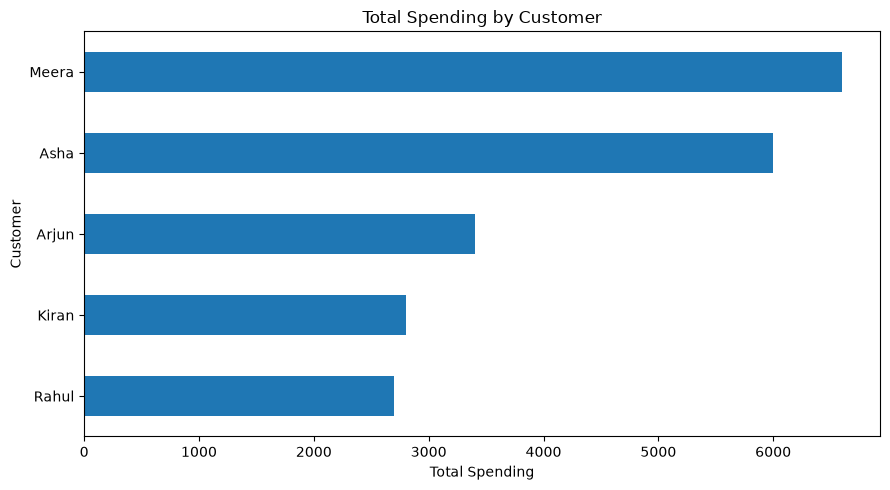

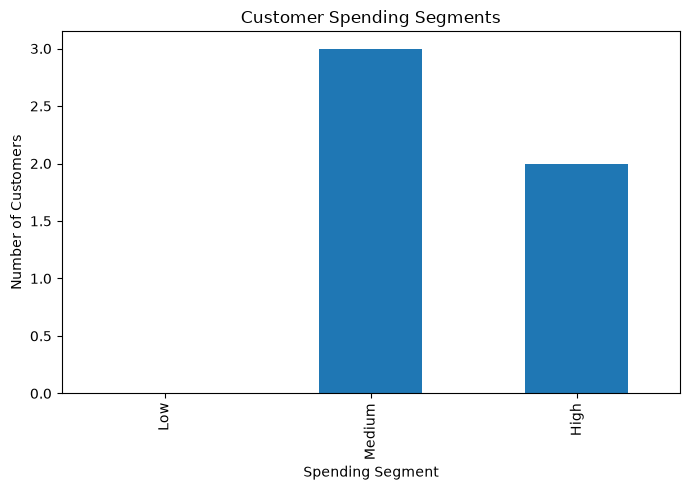

In [5]:

plt.figure(figsize=(9, 5))
customer_summary["total_spent"].sort_values().plot(kind="barh")
plt.title("Total Spending by Customer")
plt.xlabel("Total Spending")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
segment_counts.plot(kind="bar")
plt.title("Customer Spending Segments")
plt.xlabel("Spending Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [6]:

customer_category = pd.pivot_table(
    df,
    index="customer",
    columns="category",
    values="sales",
    aggfunc="sum",
    fill_value=0
)

display(customer_category)

customer_category.to_csv(
    OUTPUT_DIR / "customer_category_preferences.csv"
)

top_customer = customer_summary["total_spent"].idxmax()
highest_spending = customer_summary["total_spent"].max()

findings = [
    f"Unique customers: {df['customer'].nunique()}",
    f"Unique orders after duplicate removal: {df['order_id'].nunique()}",
    f"Highest-spending customer: {top_customer}",
    f"Highest customer spending: {highest_spending:.2f}",
    f"Most common spending segment: {segment_counts.idxmax()}",
]

findings_path = REPORT_DIR / "customer_behavior_findings.txt"
findings_path.write_text("\n".join(findings), encoding="utf-8")

print("\n".join(findings))
print("\nFindings saved to:", findings_path)


category,Clothing,Electronics,Home
customer,,,
Arjun,1800,0,1600
Asha,1800,4200,0
Kiran,1000,0,1800
Meera,0,5500,1100
Rahul,1500,0,1200


Unique customers: 5
Unique orders after duplicate removal: 12
Highest-spending customer: Meera
Highest customer spending: 6600.00
Most common spending segment: Medium

Findings saved to: C:\Users\Comp\Linkific-Tasks-Upload\Day 7\reports\customer_behavior_findings.txt
